In [1]:
import matplotlib.pyplot as plt
import numpy as np
from spanks.synthetic_sky import get_synthetic_sky_image
from spanks.noise_suppressor2D import suppress_noise2d
from astropy.convolution import Gaussian2DKernel
from scipy.signal import convolve2d

# 1. Making a synthetic sky image for the test
image_size = (1000, 1000)
noise_std = 0.4
symmetric = False

number_of_psf_sources = 40
psf_std_range = (3, 10)
psf_dynamic_range = (2.5, 5)

number_of_sersic_sources = 8
r_eff_range = (100, 150)
n_range = (1.5, 4.5)
ellip_range = (0, 0.8)
theta_range = (0, np.pi)
sersic_dynamic_range = (2, 4.5)
np.random.seed(42) # Change to generate a different sky
gradient_level = 0.0
gradient_slope = 0

sky_image = get_synthetic_sky_image(image_size, noise_std, number_of_psf_sources, psf_std_range, psf_dynamic_range, number_of_sersic_sources, r_eff_range, n_range, ellip_range, theta_range, sersic_dynamic_range, gradient_level, gradient_slope, symmetric)

sky_image_flat_bkg = sky_image # In case next step is omitted

In [2]:
"""This step is optional but recommended if image has a non-constant background"""
# 2. Subtracting background gradient
from photutils.segmentation import detect_threshold, detect_sources
from photutils.background import Background2D, SExtractorBackground, MADStdBackgroundRMS

# 2.1 Detecting all sources in image to mask from background
src_detection_kernel = Gaussian2DKernel(2.0)
image_convolved = convolve2d(sky_image, src_detection_kernel, mode='same', boundary='symm')
det_threshold = detect_threshold(image_convolved, n_sigma = 5)
seg_map = detect_sources(image_convolved, det_threshold, n_pixels = 10, connectivity=8)
sources_mask = seg_map.make_source_mask(size=1)

# 2.2 Estimating background
bkg = Background2D(sky_image, box_size=(16, 16), mask=sources_mask, filter_size = (5,5), exclude_percentile=5,
                   bkg_estimator=SExtractorBackground(), bkg_rms_estimator=MADStdBackgroundRMS())
bkg_image = bkg.background
sky_image_flat_bkg = sky_image - bkg_image


In [3]:
from spanks.utils import sigma_clipping
import numpy as np
from scipy.stats import norm
from scipy.signal import convolve2d
from scipy.special import expit, logit
from astropy.convolution import Gaussian2DKernel
from spanks.noise_suppressor2D import _get_p_layers2d, _get_p_simple2d, _get_p_logit2d, _apply_p_map, mean_neighbors2d, prod_neighbors2d, heavy_neighbors2d

image_noise_lvl, image_noise_std = sigma_clipping(sky_image, robust=False)
kernel = Gaussian2DKernel(2.0).array.copy()
# Probability of obtaining x or lower:
if symmetric:
    noise_p_map = norm.cdf(np.abs(sky_image), loc=image_noise_lvl, scale=image_noise_std)
else:
    noise_p_map = norm.cdf(sky_image, loc=image_noise_lvl, scale=image_noise_std)
method = "simple"
if method == "logit":
    p_map = _get_p_logit2d(noise_p_map, kernel, alpha = 1.0)
elif method == "layers":
    p_map = _get_p_layers2d(sky_image, noise_p_map, kernel, symmetric, square_map = False)
else: #simple
    p_map = _get_p_simple2d(noise_p_map, kernel)


neighbors_weight = 0.5
neighbors_strength = 2
heavy_baseline = None
heavy_average_weights = False
p_map_mean = mean_neighbors2d(p_map, sky_image, noise_p_map, kernel, method, neighbors_weight=neighbors_weight)
p_map_prod = prod_neighbors2d(p_map, sky_image, noise_p_map, kernel, method)
p_map_heavy = heavy_neighbors2d(p_map, kernel, neighbors_strength=neighbors_strength, baseline=heavy_baseline, average_weights = heavy_average_weights)

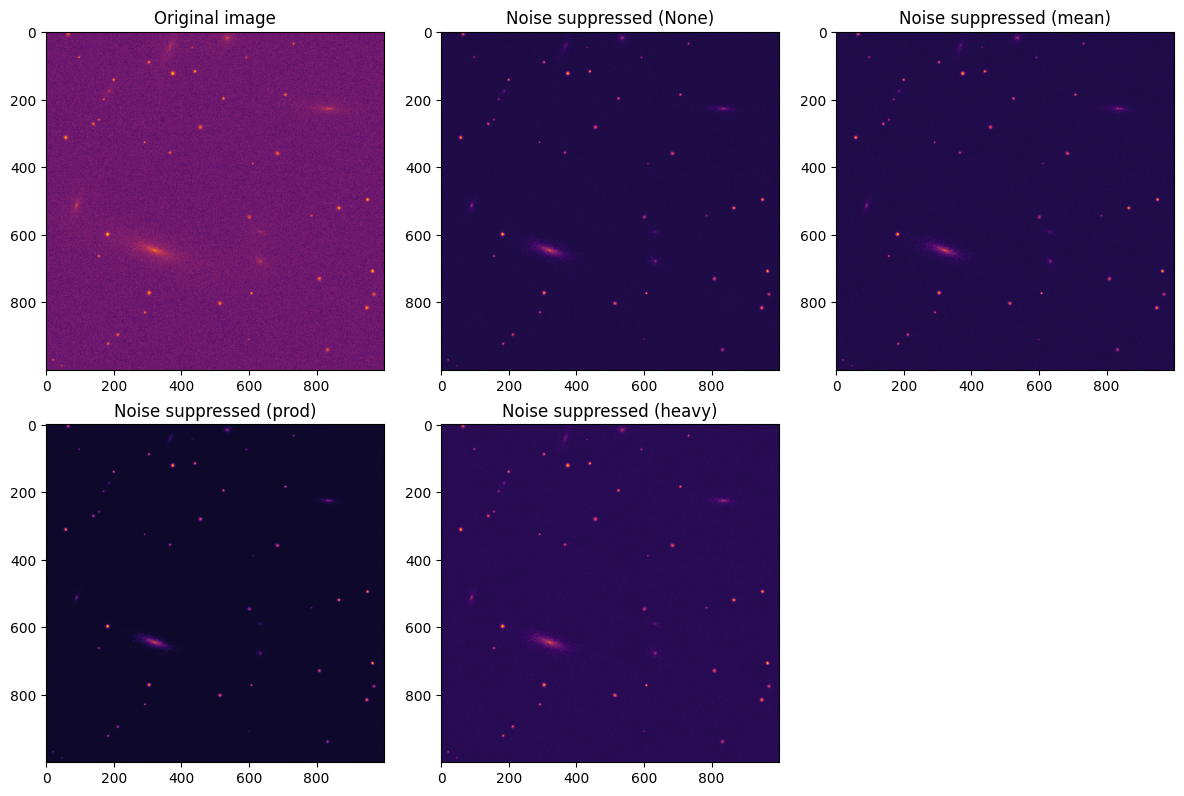

In [6]:
# 3. Suppressing image noise with different boosters
# Choose one of the methods
# method = "simple"
# method = "logit"
method = "layers"

sky_image_booster_none = suppress_noise2d(sky_image_flat_bkg, method=method, symmetric = symmetric, neighbor_booster = None)
sky_image_booster_mean = suppress_noise2d(sky_image_flat_bkg, method=method, symmetric = symmetric, neighbor_booster = "mean")
sky_image_booster_prod = suppress_noise2d(sky_image_flat_bkg, method=method, symmetric = symmetric, neighbor_booster = "product")
sky_image_booster_heavy = suppress_noise2d(sky_image_flat_bkg, method=method, symmetric = symmetric, neighbor_booster = "heavy", neighbors_strength = 1, heavy_baseline=None)



cmap = "inferno"
# 4. Plotting results
fig, ax = plt.subplots(2,3, figsize = (12,8))
ax[0,0].imshow(sky_image, cmap = cmap)
ax[0,0].set_title("Original image")
ax[0,1].imshow(sky_image_booster_none, cmap = cmap)
ax[0,1].set_title("Noise suppressed (None)")
ax[0,2].imshow(sky_image_booster_mean, cmap = cmap)
ax[0,2].set_title("Noise suppressed (mean)")
ax[1,0].imshow(sky_image_booster_prod, cmap = cmap)
ax[1,0].set_title("Noise suppressed (prod)")
ax[1,1].imshow(sky_image_booster_heavy, cmap = cmap)
ax[1,1].set_title("Noise suppressed (heavy)")
ax[1,2].set_visible(False)
plt.tight_layout()
plt.show()
